P1 - IDIG4120 

Group members: Filza Akhlaq and Akanksha More

Submitted to: Steven Yves Le Moan

This notebook is divided in seven main sections as per the requirements of P2. 

Build a compression path you can explain completely, test it on data it has not seen, and account for every byte.
The aim is not a competitive compression ratio.

![Interface Image](./interface-img.png)


In [12]:
import matplotlib.pyplot as plt
import os
from pathlib import Path
from PIL import Image
import random
import numpy as np

# 1. A lossless or lossy design with every stage named and justified.

Proposed compression: Lossy JPEG style compression, but doing it manually in this notebook.

The pipeline would look something like: Original RGB image → Compression → Decompression → Reconstructed RGB image

## In detail:


| Compression (Encoder) | Decompression (Decoder) |
|:---:|:---:|
| **Original RGB Image** | **Compressed Bytes + Metadata** |
| ↓ | ↓ |
| Separate RGB Channels | Entropy Decoding |
| ↓ | ↓ |
| Split into 8×8 Blocks (with padding if needed) | Reverse RLE + Zigzag |
| ↓ | ↓ |
| Apply DCT | Dequantise Coefficients |
| ↓ | ↓ |
| Quantise Coefficients | Apply Inverse DCT |
| ↓ | ↓ |
| Zigzag Ordering + RLE | Reassemble Blocks and Remove Padding |
| ↓ | ↓ |
| Entropy Encoding | Combine RGB Channels |
| ↓ | ↓ |
| **Compressed Bytes + Metadata** | **Reconstructed RGB Image** |

**Note:** Our codec is lossy because quantisation removes some information. The reconstructed image will have the same dimensions and three colour channels as the original, but some pixel values may be different.


transistor
capsule
metal_nut
pill
hazelnut


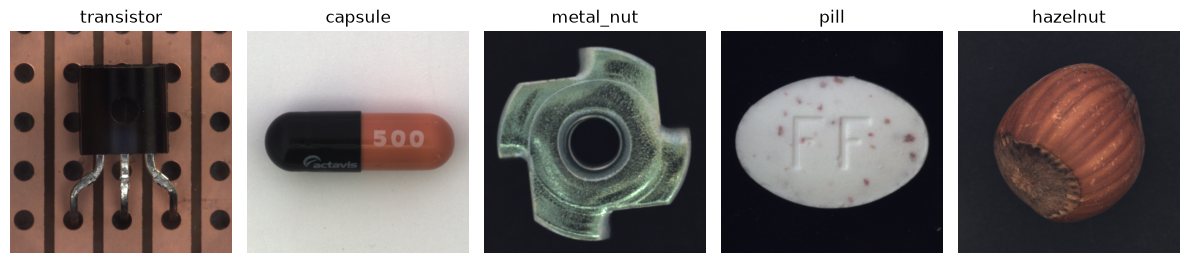

In [14]:
# creating a dictionary of images from the dataset and append the info such as
# filetype, shape, image size, datatype to each image
data_dict = {}
rdir = "./final_dataset"

for objecttype in os.listdir(rdir):
    object_path = Path(rdir) / objecttype

    # Skip files which are not directories
    if not object_path.is_dir():
        continue

    object_dir = object_path / 'train'
    print(objecttype)

    for imgpath in object_dir.iterdir():
        if not imgpath.is_file():
            continue

        if objecttype not in data_dict:
            data_dict[objecttype] = []

        img = Image.open(imgpath)
        img_np = np.array(img)

        data_dict[objecttype].append((
            imgpath,
            imgpath.suffix,
            img_np.shape,
            imgpath.stat().st_size,
            img_np.dtype
        ))

# function to get a random image from the dataset
def get_one_random_image(data_dict, objecttype:str = None) -> Path:
    objtype = objecttype or random.choice(list(data_dict.keys()))
    return random.choice(data_dict[objtype])

# A function that displays images with different parameters such as axes, title, label
def display_image(img, cmap: str = None, title: str = None, 
                  axes: bool = True, figsize=(4, 4),
                  xlabel: str = None, ylabel: str = None, xticks: list = None, yticks: list = None, ax=None):
    
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
        
    ax.imshow(img, cmap=cmap)

    if title is not None:
        ax.set_title(title)

    if xlabel is not None:
        ax.set_xlabel(xlabel)

    if ylabel is not None:
        ax.set_ylabel(ylabel)

    if not axes:
        ax.axis('off')
        
    if xticks is not None:
        ax.set_xticks(xticks)
        
    if yticks is not None:
        ax.set_yticks(yticks)
        
    return ax


# using the loader created in P1

fig, axes = plt.subplots(1, len(data_dict), figsize=(12, 3))

for ax, objecttype in zip(axes, data_dict):
    obj = get_one_random_image(data_dict, objecttype)
    imgpath = obj[0]

    img = Image.open(imgpath)

    display_image(img, title=objecttype, axes=False, ax=ax)

plt.tight_layout()
plt.show()

# 2. Tests for shape, data type, empty and tiny inputs, and one unseen file.

# 3. A genuine byte count, or a defined coded-bit estimate that includes the side information.

# 4. Lossless: exact round-trip tests. Lossy: a rate–quality curve with a named metric.

# 5. A comparison against one baseline, at comparable settings.

# 6. One documented failure, or a setting where your method should not be used.

# 7. Run instructions, fixed seeds, who did what, and the generative-AI declaration.
Run instructions:

Fixed seeds:

Akanksha: 

Filza:

Generative-AI declaration:
